# Práctica 0 - MLP

Se implementa desde cero una red neuronal **MLP** con una capa oculta.

La red utilizada tiene:

- `input_size` neuronas de entrada, una por cada variable de `X_train`.
- Una capa oculta de `hidden_size = 10` neuronas con función de activación sigmoide.
- Una neurona de salida con activación lineal, adecuada para un problema de regresión.
- Entrenamiento mediante **backpropagation** y descenso de gradiente.
- Función de pérdida: **Mean Squared Error (MSE)**.

Durante el entrenamiento se guarda el MSE de cada época para poder representar la evolución del error.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
class MLP:
    def __init__(self, input_size, hidden_size, output_size=1, learning_rate=0.01,epochs=1000,seed=42):

        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.seed = seed
        self.loss_history = []
        
    
        np.random.seed(self.seed)

        # Pesos entre la capa de entrada y la capa oculta
        self.W1 = np.random.randn(self.input_size, self.hidden_size) * 0.1
        # Sesgos de la capa oculta
        self.b1 = np.zeros((1, self.hidden_size))
        # Pesos entre la capa oculta y la capa de salida.
        self.W2 = np.random.randn(self.hidden_size, self.output_size) * 0.1
        # Sesgo de la capa de salida
        self.b2 = np.zeros((1, self.output_size))


    def sigmoid(self, x): 
        return 1 / (1 + np.exp(-x))

    def sigmoid_derivative(self, x):
        return x * (1 - x)

    def fit(self, X, y):

        n_samples = X.shape[0]
        self.loss_history = []

        for epoch in range(self.epochs):
        
            # Entrada de la capa oculta
            z1 = np.dot(X, self.W1) + self.b1
            # Salida de la capa oculta
            a1 = self.sigmoid(z1)
            # Entrada de la capa de salida
            z2 = np.dot(a1, self.W2) + self.b2
            # Salida de la capa de salida (lineal)
            a2 = z2

            error_mse = np.mean((a2 - y) ** 2)
            self.loss_history.append(error_mse)

            # Derivada del MSE respecto a la salida
            dZ2 = 2.0 * (a2 - y) / n_samples

            # Gradiente de los pesos de la capa de salida
            dW2 = np.dot(a1.T, dZ2)
            # Gradiente del sesgo de la capa de salida
            db2 = np.sum(dZ2, axis=0, keepdims=True)

            # Propagación hacia atrás a la capa oculta
            dA1 = np.dot(dZ2, self.W2.T)
            dZ1 = dA1 * self.sigmoid_derivative(a1)

            dW1 = np.dot(X.T, dZ1)
            db1 = np.sum(dZ1, axis=0, keepdims=True)

            # Descenso de gradiente
            self.W1 -= self.learning_rate * dW1
            self.b1 -= self.learning_rate * db1
            self.W2 -= self.learning_rate * dW2
            self.b2 -= self.learning_rate * db2

    def predict(self, X):
        z1 = np.dot(X, self.W1) + self.b1
        a1 = self.sigmoid(z1)
        z2 = np.dot(a1, self.W2) + self.b2
        return z2

    def plot_error(self):
        plt.plot(self.loss_history)
        plt.xlabel('Epochs')
        plt.ylabel('Mean Squared Error')
        plt.title('Training Error over Epochs')
        plt.grid()
        plt.show()

Training the model


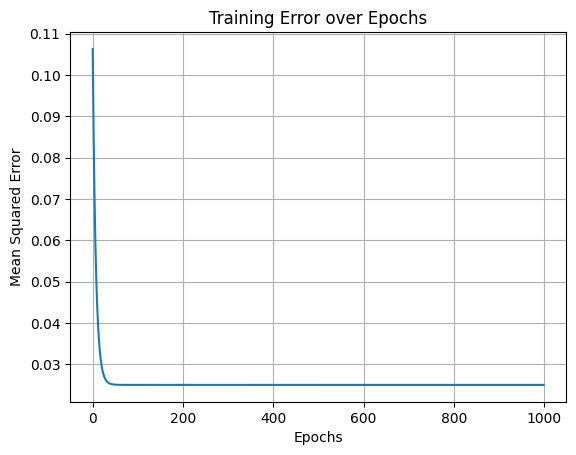

In [17]:
df = pd.read_parquet('data_train.parquet')

X_train = df.iloc[:, :-1].values
y_train = df.iloc[:, -1].values.reshape(-1, 1)

X_train = (X_train - np.mean(X_train, axis=0)) / np.std(X_train, axis=0)

model = MLP(input_size=X_train.shape[1], hidden_size=10, learning_rate=0.01, epochs=1000,seed=42)

print("Training the model")
model.fit(X_train, y_train)

model.plot_error()